In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ALPHA = 0.5
BETA = 0.2
DESIRED_GAP = 10.0
DT = 1.0
# -----------------------------
# Initial modelling assumptions
# -----------------------------
VEHICLE_LENGTH = 4.5  # m

# Display settings
FIG_WIDTH = 12
FIG_HEIGHT = 3

In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "assignment_initial_conditions.csv"

print("Current directory:", Path.cwd())
print("Project root:", PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT))

df = pd.read_csv(DATA_PATH)
df = df.sort_values("position_m", ascending=False).reset_index(drop=True)

df

Current directory: e:\Job Search\Phd Applications\KU Leuven\assignment\notebooks
Project root: e:\Job Search\Phd Applications\KU Leuven\assignment


,vehicle_id,position_m,speed_mps,type
0,0,199.50,13.83,HDV
1,1,187.52,15.04,HDV
2,2,172.36,17.25,HDV
3,3,157.54,16.32,HDV
4,4,141.48,14.91,HDV
5,5,127.20,18.12,HDV
6,6,112.52,13.39,HDV
7,7,101.46,14.92,AV
8,8,86.12,15.66,HDV
9,9,72.26,16.56,HDV


In [3]:
df["gap_m"] = np.nan

leader_positions = df["position_m"].iloc[:-1].to_numpy()
follower_positions = df["position_m"].iloc[1:].to_numpy()

gaps = leader_positions - follower_positions - VEHICLE_LENGTH

df.loc[1:, "gap_m"] = gaps

print(
    df[
        ["vehicle_id", "position_m", "speed_mps", "type", "gap_m"]
    ].to_string(index=False)
)

 vehicle_id  position_m  speed_mps type  gap_m
          0      199.50      13.83  HDV    NaN
          1      187.52      15.04  HDV   7.48
          2      172.36      17.25  HDV  10.66
          3      157.54      16.32  HDV  10.32
          4      141.48      14.91  HDV  11.56
          5      127.20      18.12  HDV   9.78
          6      112.52      13.39  HDV  10.18
          7      101.46      14.92   AV   6.56
          8       86.12      15.66  HDV  10.84
          9       72.26      16.56  HDV   9.36
         10       55.23      19.85   AV  12.53
         11       44.74      14.00  HDV   5.99
         12       29.90      17.14   AV  10.34
         13       13.14      17.92  HDV  12.26
         14       -1.27      12.46   AV   9.91


In [4]:
valid_gaps = df["gap_m"].dropna()

if (valid_gaps <= 0).any():
    print("WARNING: At least one vehicle has a non-positive gap.")
else:
    print("All initial vehicle gaps are positive.")

print(f"Minimum gap: {valid_gaps.min():.2f} m")
print(f"Mean gap:    {valid_gaps.mean():.2f} m")
print(f"Maximum gap: {valid_gaps.max():.2f} m")

All initial vehicle gaps are positive.
Minimum gap: 5.99 m
Mean gap:    9.84 m
Maximum gap: 12.53 m


In [5]:
df["initial_accel_mps2"] = np.nan

for i in range(1, len(df)):
    if df.loc[i, "type"] == "HDV":

        v = df.loc[i, "speed_mps"]
        v_lead = df.loc[i - 1, "speed_mps"]
        gap = df.loc[i, "gap_m"]

        acceleration = (
            ALPHA * (v_lead - v)
            + BETA * (gap - DESIRED_GAP)
        )

        df.loc[i, "initial_accel_mps2"] = acceleration

df[
    [
        "vehicle_id",
        "type",
        "position_m",
        "speed_mps",
        "gap_m",
        "initial_accel_mps2"
    ]
]

hdv_acc = df["initial_accel_mps2"].dropna()

print(df)
print(f"Minimum HDV acceleration: {hdv_acc.min():.2f} m/s²")
print(f"Maximum HDV acceleration: {hdv_acc.max():.2f} m/s²")

    vehicle_id  position_m  speed_mps type  gap_m  initial_accel_mps2
0            0      199.50      13.83  HDV    NaN                 NaN
1            1      187.52      15.04  HDV   7.48              -1.109
2            2      172.36      17.25  HDV  10.66              -0.973
3            3      157.54      16.32  HDV  10.32               0.529
4            4      141.48      14.91  HDV  11.56               1.017
5            5      127.20      18.12  HDV   9.78              -1.649
6            6      112.52      13.39  HDV  10.18               2.401
7            7      101.46      14.92   AV   6.56                 NaN
8            8       86.12      15.66  HDV  10.84              -0.202
9            9       72.26      16.56  HDV   9.36              -0.578
10          10       55.23      19.85   AV  12.53                 NaN
11          11       44.74      14.00  HDV   5.99               2.123
12          12       29.90      17.14   AV  10.34                 NaN
13          13      

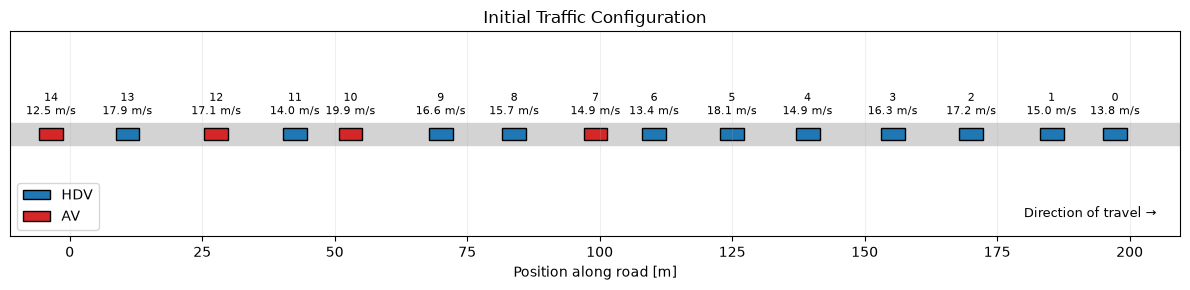

In [6]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))

VEHICLE_HEIGHT = 0.2
ROAD_Y = 0.0
ROAD_HEIGHT = VEHICLE_HEIGHT + 0.2

# Road
ax.add_patch(
    plt.Rectangle(
        (df["position_m"].min() - 10, -ROAD_HEIGHT / 2),         # bottom-left corner of the road
        df["position_m"].max() - df["position_m"].min() + 20,    # length of the road in x 
        ROAD_HEIGHT,                                             # width of the road in y
        facecolor="lightgray",
        edgecolor="lightgray",
        linewidth=1.0
    )
)

# Vehicles
for _, row in df.iterrows():

    x = row["position_m"]

    facecolor = "tab:red" if row["type"] == "AV" else "tab:blue"

    ax.add_patch(
        plt.Rectangle(
            (x - VEHICLE_LENGTH, ROAD_Y - VEHICLE_HEIGHT / 2), # bottom-left corner of the vehicle bounding box
            VEHICLE_LENGTH,
            VEHICLE_HEIGHT,
            facecolor=facecolor,
            edgecolor="black",
            linewidth=1.0
        )
    )

    ax.text(
        x - VEHICLE_LENGTH / 2,
        VEHICLE_HEIGHT / 2 + 0.18,
        f"{int(row['vehicle_id'])}\n"
        f"{row['speed_mps']:.1f} m/s",
        ha="center",
        va="bottom",
        fontsize=8
    )

# Direction
ax.text(
    0.98, 0.08,
    "Direction of travel →",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9
)

# Axes
ax.set_xlim(
    df["position_m"].min() - 10,
    df["position_m"].max() + 10
)

ax.set_ylim(-1.8, 1.8)

ax.set_xlabel("Position along road [m]")
ax.set_yticks([])


ax.set_title("Initial Traffic Configuration")

ax.grid(axis="x", alpha=0.2)

# Legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="tab:blue", edgecolor="black", label="HDV"),
    Patch(facecolor="tab:red", edgecolor="black", label="AV")
]

ax.legend(
    handles=legend_elements,
    loc="lower left"
)

plt.tight_layout()
plt.show()

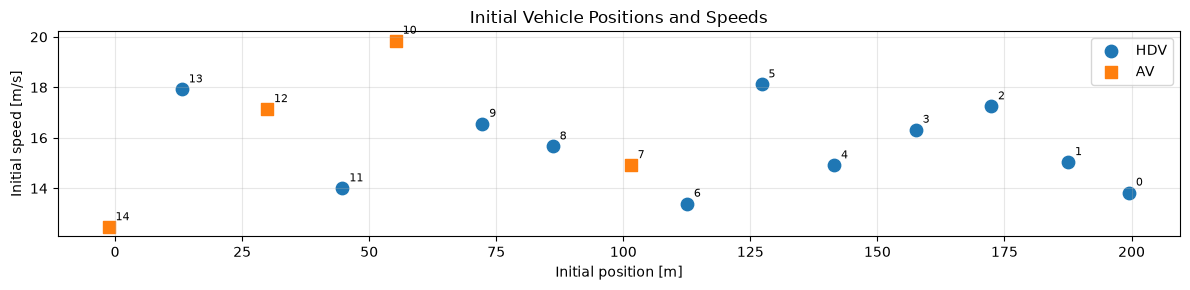

In [7]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))

for vehicle_type, marker, label in [
    ("HDV", "o", "HDV"),
    ("AV", "s", "AV"),
]:
    subset = df[df["type"] == vehicle_type]

    ax.scatter(
        subset["position_m"],
        subset["speed_mps"],
        marker=marker,
        s=80,
        label=label
    )

    for _, row in subset.iterrows():
        ax.annotate(
            int(row["vehicle_id"]),
            (row["position_m"], row["speed_mps"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

ax.set_xlabel("Initial position [m]")
ax.set_ylabel("Initial speed [m/s]")
ax.set_title("Initial Vehicle Positions and Speeds")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
from src.dataloader import load_data
from src.simulation_without_ped import simulate

df = load_data()

results = simulate(df)

print(results["speeds"][:, 0])

[13.83       14.03       14.23       14.43       14.63       14.83
 15.03       15.23       15.43       15.63       15.83       16.03
 16.2285     16.417075   16.59622125 16.76641019 16.92808968 17.08168519
 17.22760093 17.36622089 17.49790984 17.62301435 17.74186363 17.85477045
 17.96203193 18.06393033 18.16073382 18.25269713 18.34006227 18.42305916
 18.5019062  18.57681089 18.64797034 18.71557183 18.77979324 18.84080357
 18.89876339 18.95382522 19.00613396 19.05582727 19.1030359  19.14788411
 19.1904899  19.23096541 19.26941714 19.30594628 19.34064897 19.37361652
 19.40493569 19.43468891 19.46295446 19.48980674 19.5153164  19.53955058
 19.56257305 19.5844444  19.60522218 19.62496107 19.64371302 19.66152737
 19.678451   19.69452845 19.70980203 19.72431192 19.73809633 19.75119151
 19.76363194 19.77545034 19.78667782 19.79734393 19.80747673 19.8171029
 19.82624775 19.83493537 19.8431886  19.85102917 19.85847771 19.86555382
 19.87227613 19.87866233 19.88472921 19.89049275 19.89596811 19.

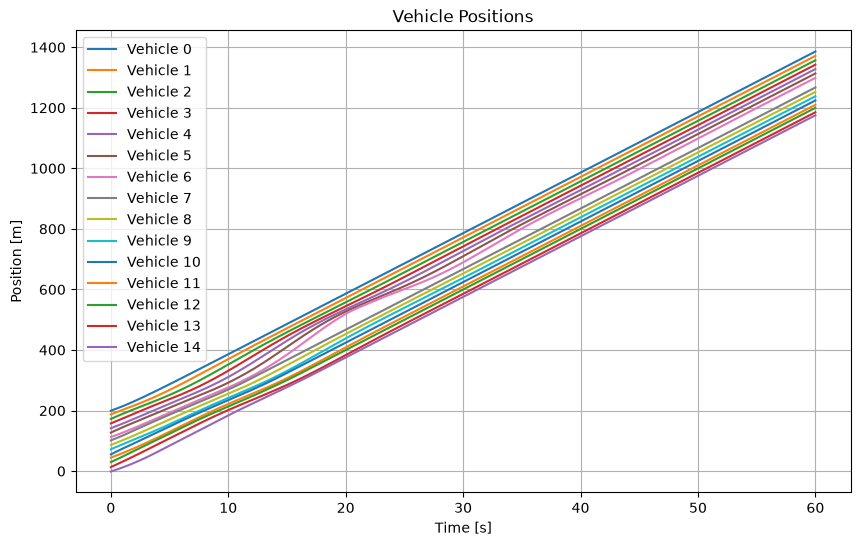

In [9]:
import matplotlib.pyplot as plt

time = results["time"]
positions = results["positions"]

plt.figure(figsize=(10, 6))
#plt.plot(time, positions[:, 8], label=f"Vehicle 8")
for i in range(positions.shape[1]):
    plt.plot(time, positions[:, i], label=f"Vehicle {i}")

plt.xlabel("Time [s]")
plt.ylabel("Position [m]")
plt.title("Vehicle Positions")
plt.legend()
plt.grid(True)
plt.show()

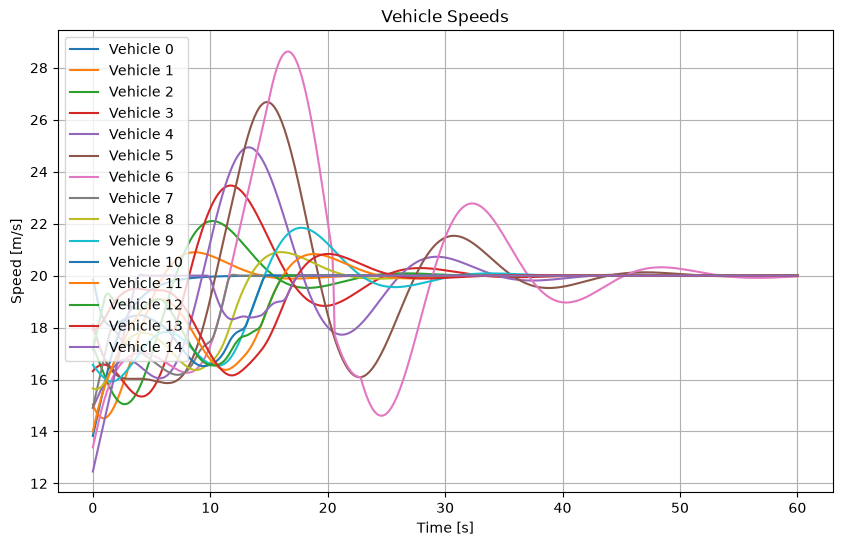

In [10]:
speeds = results["speeds"]

plt.figure(figsize=(10, 6))
#plt.plot(time, speeds[:, 8], label=f"Vehicle 8")
for i in range(speeds.shape[1]):
    plt.plot(time, speeds[:, i], label=f"Vehicle {i}")

plt.xlabel("Time [s]")
plt.ylabel("Speed [m/s]")
plt.title("Vehicle Speeds")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
import numpy as np

positions = results["positions"]
gaps = results["gaps"]

# Check vehicle ordering
ordering_ok = np.all(
    positions[:, :-1] > positions[:, 1:],
    axis=1
)

print("Vehicle ordering maintained:", ordering_ok.all())

if not ordering_ok.all():
    first_bad = np.where(~ordering_ok)[0][0]
    print("First violation at:",
          results["time"][first_bad], "s")


# Minimum gap
minimum_gap = np.nanmin(gaps)

print("Minimum gap:", minimum_gap, "m")

idx = np.unravel_index(
    np.nanargmin(gaps),
    gaps.shape
)

print("Minimum gap occurs at:")
print("Time:", results["time"][idx[0]], "s")
print("Vehicle:", idx[1])

Vehicle ordering maintained: True
Minimum gap: 2.0 m
Minimum gap occurs at:
Time: 4.4 s
Vehicle: 12


In [12]:
speeds = results["speeds"]

print("Maximum speed:", speeds.max(), "m/s")
print("Minimum speed:", speeds.min(), "m/s")

print(
    "Number of speed-limit hits:",
    np.sum(speeds >= 30.0)
)

print(
    "Number of zero-speed states:",
    np.sum(speeds <= 0.0)
)

Maximum speed: 28.62710187172274 m/s
Minimum speed: 12.46 m/s
Number of speed-limit hits: 0
Number of zero-speed states: 0


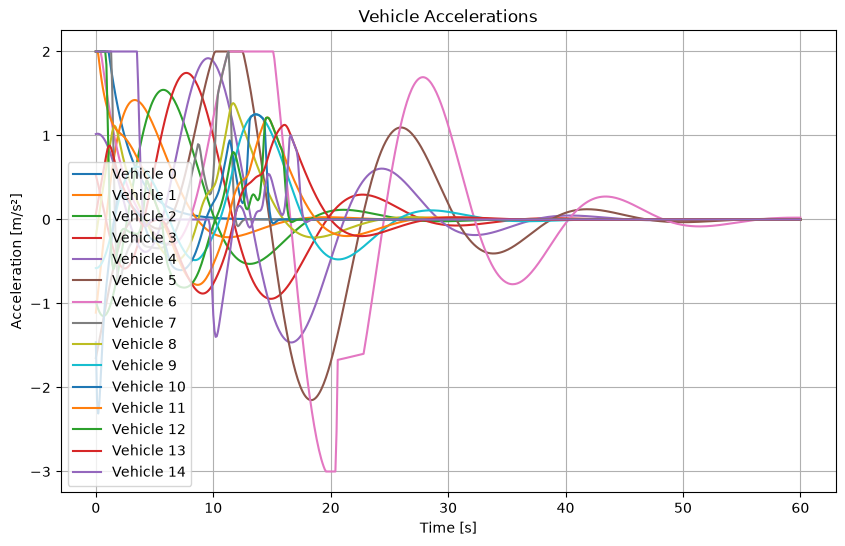

In [13]:
import matplotlib.pyplot as plt

time = results["time"]
accelerations = results["accelerations"]

plt.figure(figsize=(10, 6))

for i in range(accelerations.shape[1]):
    plt.plot(
        time,
        accelerations[:, i],
        label=f"Vehicle {i}"
    )

plt.xlabel("Time [s]")
plt.ylabel("Acceleration [m/s²]")
plt.title("Vehicle Accelerations")
plt.legend()
plt.grid(True)
plt.show()